In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import precision_recall_curve, average_precision_score

# Model evaluation on the DeepRNAi public test set

This notebook plots and compares the performance of three models trained on the public training set:

- **mini-DeepRNAi**
- **mini-DeepRNAi without biological foundation model (BioFM) embeddings**
- **mini-Random Forest**

All models are evaluated on the public test set using the following metrics:

- **On-target prediction:** Pearson correlation
- **Near-perfect match (NPM) off-target prediction:** average precision
- **Seed-match off-target prediction:** average precision

In [2]:
def bootstrap_correlation(
    df: pd.DataFrame,
    pred_columns: list[str],
    n_reps: int=2000,
    seed: int=55,
) -> np.ndarray:
    """
    Bootstrap the Pearson correlation for on-target predictions 
    vs. observed values for each model.

    Parameters:
    df : pd.DataFrame
        DataFrame containing `sirna_id`, the observed values 'log2fc_centered',
        and the prediction columns specified by `pred_columns`.
    pred_columns : list of str
        List of column names containing the model predictions.
    n_reps : int, optional
        Number of bootstrap repetitions (default is 2000).
    seed : int
        Seed used to initialize the bootstrap random number
        generator for reproducibility (default is 55).

    Returns:
    np.ndarray
        Array of shape (n_reps, n_models) containing the Pearson
        correlation coefficient for each model in each bootstrap
        replicate.
    """

    df = df.copy()
    # drop rows with missing predictions from any of the models or data
    df = df.dropna(subset=["log2fc_centered", *pred_columns])

    sirnas = df.sirna_id.unique()
    df_by_sirna = df.set_index("sirna_id")

    corrs = []
    
    # use fixed seed
    rng = np.random.default_rng(seed)
    
    for _ in range(n_reps):
        r_temp = []
        # Randomly select siRNAs, and subset on those
        sirnas_rep = rng.choice(sirnas, size=len(sirnas), replace=True)
        df_temp = df_by_sirna.loc[sirnas_rep].reset_index()
        observed = df_temp.log2fc_centered.values
        preds = np.stack([df_temp[c].values for c in pred_columns], axis=1)
        
        # calculate the Pearson R for each model
        for i in range(len(pred_columns)):
            pearson_r = stats.pearsonr(observed, preds[:, i])[0]
            r_temp.append(pearson_r)
        corrs.append(np.array(r_temp))
    return np.array(corrs)


def bootstrap_ap(
    df: pd.DataFrame, 
    pred_columns: list[str], 
    n_reps: int = 2000, 
    effect_threshold: float=-0.5, 
    p_threshold: float=0.05,
    seed: int=55,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float]:
    """
    Bootstrap average precision (AP) scores and precision-recall (PR) curves
    for each model.

    Parameters:
        df : pd.DataFrame
            DataFrame containing `sirna_id`, the observed values 'log2fc_centered',
            the prediction columns specified by `pred_columns`, and
            the p-values in 'padj_diffexp'.
        pred_columns : list of str
            List of column names containing the model predictions.
        n_reps : int, optional
            Number of bootstrap repetitions (default is 2000).
        effect_threshold : float, optional
            Effect size threshold for defining hits, applied to 'log2fc_centered'
            (default is -0.5).
        p_threshold : float, optional
            P-value threshold for defining hits, applied to 'padj_diffexp'
            (default is 0.05).
        seed : int
            Seed used to initialize the bootstrap random number
            generator for reproducibility (default is 55).
        

    Returns:
        avg_precision : numpy.ndarray
            Array of shape (n_reps, n_models) containing average precision
            scores for each model in each bootstrap replicate.
        precision_curves : numpy.ndarray
            Array of shape (n_reps, n_models, 100) containing interpolated
            precision values for each model and bootstrap replicate.
        recall_smooth : numpy.ndarray
            Array of 100 evenly spaced recall values between 0 and 1
            used for interpolating the PR curves.
        baseline : float
            Proportion of positive observations in the dataset after filtering.
    """
    df = df.copy()
    
    # remove data points with effect < effect_threshold and padj_diffexp > p_threshold
    # these are not considered for the classification task
    df = df[~(
        (df.log2fc_centered < effect_threshold) &
        (df.padj_diffexp > p_threshold))
    ]
    # drop rows with missing predictions from any of the models
    df = df.dropna(subset=["log2fc_centered", *pred_columns])
    # get the baseline hit rate
    targets = (
        (df.log2fc_centered < effect_threshold) &
        (df.padj_diffexp < p_threshold)
    )
    baseline = np.mean(targets)
    
    # prepare for bootstrapping
    sirnas = df.sirna_id.unique()
    df_by_sirna = df.set_index("sirna_id")

    recall_smooth = np.linspace(0, 1, 100)

    avg_precision = []
    precision_curves = []
    
    rng = np.random.default_rng(seed)

    for _ in range(n_reps):
        
        avg_precision_temp = []
        precision_temp = []

        # randomly select siRNAs, and subset on those
        sirnas_rep = rng.choice(sirnas, size=len(sirnas), replace=True)
        df_temp = df_by_sirna.loc[sirnas_rep].reset_index()

        observed = df_temp.log2fc_centered.values
        p_vals = df_temp.padj_diffexp.values
        preds = np.stack([df_temp[c].values for c in pred_columns], axis=1)
        targets = np.float32((observed < effect_threshold) * (p_vals < p_threshold))

        # calculate the average precision (AP) for each model
        for i in range(len(pred_columns)):
            ap = average_precision_score(targets, -preds[:, i])
            precision, recall, thresholds = precision_recall_curve(targets, -preds[:, i])
            precision_smooth = np.interp(recall_smooth, recall[::-1], precision[::-1])
            avg_precision_temp.append(ap)
            precision_temp.append(precision_smooth)

        avg_precision.append(np.array(avg_precision_temp))
        precision_curves.append(np.array(precision_temp))

    return np.array(avg_precision), np.array(precision_curves), recall_smooth, baseline



In [3]:
df = pd.read_csv("../data/deeprnai_dataset.csv.gz")

# subset to just the test split
df = df[df.split == "test"]
df.head(3)

,sirna_id,sirna_guide_seq,sirna_synthesis,readout_transcript_id,readout_gene_name,target_gene_name,target_transcript_id,cell_line,chemistry,format,split,baseline_tpm,log2fc_centered,padj_diffexp,best_match_type,mini_deeprnai_preds,mini_deeprnai_no_biofms_preds,mini_random_forest_preds
0,SIDP1173,TAGCGGCGGGGCTTAATGTTGCA,1.0,NM_000014.6,A2M,SLC29A1,NM_001304466.2,hepg2,chemistry1,format1,test,6545.076667,0.331348,0.143697,Other,0.006226,0.014526,0.053393
1,SIDP1173,TAGCGGCGGGGCTTAATGTTGCA,1.0,NM_000016.6,ACADM,SLC29A1,NM_001304466.2,hepg2,chemistry1,format1,test,76.176200,0.107924,0.675662,Other,0.002411,0.010292,NaN
2,SIDP1173,TAGCGGCGGGGCTTAATGTTGCA,1.0,NM_000017.4,ACADS,SLC29A1,NM_001304466.2,hepg2,chemistry1,format1,test,17.085433,0.103386,0.777290,Other,0.022827,0.020691,NaN


In [4]:
# distribution of match types
df.best_match_type.value_counts()

best_match_type
Other                403929
UTR3 6mer seed        50052
UTR3 7mer_A1 seed     36634
UTR3 7mer_m8 seed     30466
UTR3 8mer seed        20856
NPM (15mer)           15805
On target                82
Name: count, dtype: int64

In [5]:
# add a column indicating whether the best match type is a seed match (7mer or 8mer only)
df["seed_match"] = False
df.loc[df.best_match_type.isin(["UTR3 7mer_A1 seed", "UTR3 7mer_m8 seed", "UTR3 8mer seed"]), "seed_match"] = True
df.seed_match.value_counts()

seed_match
False    469868
True      87956
Name: count, dtype: int64

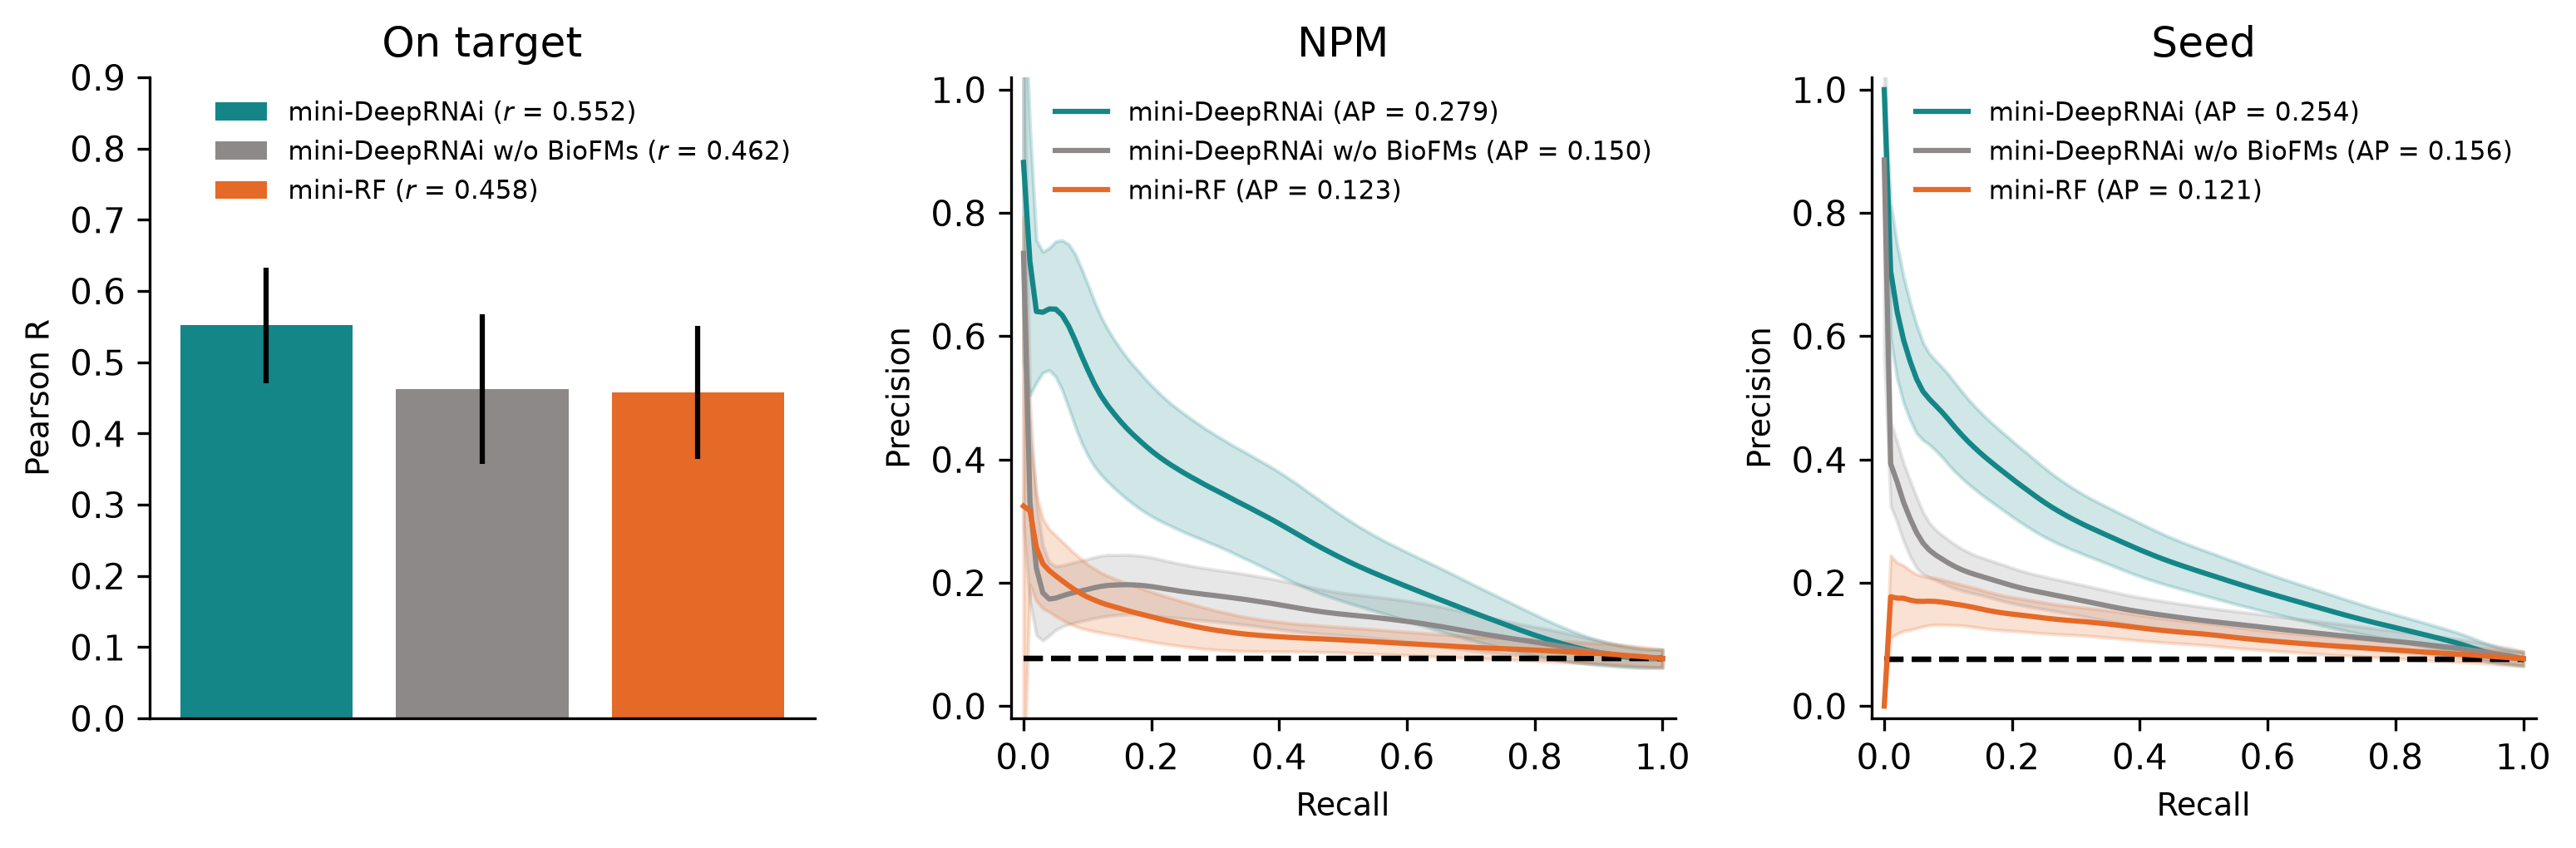

In [8]:
# plot the model comparison (Figure S5 in the preprint)
# NOTE: resulting metrics may slightly differ than those reported in the paper
# due to the different random seed used for the bootstrap analysis
# in this example, we have now set a fixed seed

seed = 1

f, ax = plt.subplots(1, 3, figsize=(10.5, 3.5), dpi=300)
fs = 9

match_types = ["On target", "NPM", "Seed"]
prediction_columns = ["mini_deeprnai_preds", "mini_deeprnai_no_biofms_preds", "mini_random_forest_preds"]

models = ["mini-DeepRNAi", "mini-DeepRNAi w/o BioFMs", "mini-RF"]
model_colors = {
    "mini-DeepRNAi": "#148687", 
    "mini-DeepRNAi w/o BioFMs": "#8D8989", 
    "mini-RF": "#E56927"
}

# number of bootstrap reps
n_reps = 2000

for j, match_type in enumerate(match_types):


    if match_type == "On target":
        df_match = df[df.best_match_type == "On target"]
        corrs = bootstrap_correlation(df_match, prediction_columns, n_reps=n_reps, seed=seed)
        means = np.mean(corrs, axis=0)
        std_dev = np.std(corrs, axis=0)

        ax[j].bar(models, means, yerr=std_dev, color=model_colors.values())
        ax[j].set_xticks([])
        ax[j].set_ylabel("Pearson R", fontsize=fs)
        ax[j].set_ylim([0.0, 0.9])
        ax[j].set_title(f"{match_type}")

        # Create manual handles for the legend
        legend_elements = [
            Patch(facecolor=model_colors[model], label=f"{model} ($r$ = {means[n]:1.3f})") for n, model in enumerate(models)
        ]
        ax[j].legend(handles=legend_elements, fontsize=fs-1.5, frameon=False)
        ax[j].spines[["top", "right"]].set_visible(False)
            
    else:
        if match_type == "NPM":
            df_match = df[df.best_match_type == "NPM (15mer)"]
        elif match_type == "Seed":
            df_match = df[df.seed_match]

        avg_precision, precision, recall, baseline = bootstrap_ap(
            df_match, 
            prediction_columns, 
            n_reps=n_reps, 
            effect_threshold=-0.5, 
            p_threshold=0.05,
            seed=seed
        )

        for n, model in enumerate(models):

            avg_prec = np.mean(avg_precision[:, n])
            means = np.mean(precision[:, n, :], axis=0)
            std_dev = np.std(precision[:, n, :], axis=0)
            ax[j].plot([0,1], [baseline, baseline], "k--")
            ax[j].plot(recall, means, label=f"{model} (AP = {avg_prec:1.3f})", color=model_colors[model])
            ax[j].fill_between(recall, means-std_dev, means+std_dev, color=model_colors[model], alpha=0.2)

            ax[j].legend(fontsize=fs-1.5, frameon=False)
            ax[j].set_xlim([-0.02, 1.02])
            ax[j].set_ylim([-0.02, 1.02])
            ax[j].set_ylabel("Precision", fontsize=fs)
            ax[j].set_xlabel("Recall", fontsize=fs)
            ax[j].set_title(f"{match_type}")
            ax[j].spines[["top", "right"]].set_visible(False)


plt.tight_layout()
plt.show()
